# Le vrai prix de la ville
## Analyse descriptive des prix de vente des appartements selon la distance à la station de métro ou de RER la plus proche, à Paris et en petite couronne (2021-2025)

### 1. Contexte et problématique

La proximité d'une station de métro ou de RER facilite les déplacements quotidiens et peut donc être recherchée par les acheteurs. Cette relation n'est pas forcément simple : un logement collé à une station peut subir du bruit et de l'affluence, et les marchés de Paris et de la petite couronne n'ont ni le même niveau de prix ni la même densité de réseau.

**Périmètre.** Seules les stations de **métro et de RER** sont prises en compte (fichier Île-de-France Mobilités, modes `METRO` et `RER`). Le tramway et les trains Transilien ne le sont pas : en petite couronne, un logement proche d'un tram ou d'une gare Transilien mais loin du métro et du RER est donc compté comme « loin ». Cela tend à atténuer les écarts mesurés.

**Problématique.** Dans quelle mesure la distance à la station de métro ou de RER la plus proche est-elle associée au prix au m² des appartements à Paris et en petite couronne ? Certaines distances se distinguent-elles, et la relation est-elle la même dans l'espace et dans le temps ?

### 2. Objectifs de ce notebook

- décrire le prix au m² selon la distance à la station, à Paris et en petite couronne ;
- vérifier si les profils tiennent avec des tranches plus fines (50 m) et d'une année à l'autre ;
- séparer ce qui vient de la distance de ce qui vient de la **composition** des ventes (dans quelles communes elles se trouvent) ;
- comparer les écarts à l'intérieur des communes et chercher d'éventuels intervalles de distance favorables ;
- comparer métro et RER à zone constante.

### 3. Démarche

Le travail est uniquement descriptif : effectifs, médianes, quantiles et écarts relatifs, sans modèle. Ce notebook ne calcule pas d'intervalles de confiance : ils sont dans le notebook `02_analyse_finale.ipynb`, qui compare des ventes de même commune, même année et même taille, et qui sert de référence pour les chiffres de la conclusion du projet.

In [1]:

from pathlib import Path
import sys

# Déterminer la racine du projet
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Ajouter le dossier src au chemin Python
SRC = ROOT / "src"

if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

print("Racine du projet :", ROOT)
print("Dossier src :", SRC)


Racine du projet : /home/onyxia/work/Projet_Data_2A_S1
Dossier src : /home/onyxia/work/Projet_Data_2A_S1/src


In [2]:
import pandas as pd
from IPython.display import display

from vrai_prix import analysis as A
from vrai_prix import visualization as V

V.style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

### 4. Sources de données

**Les Demandes de valeurs foncières (DVF géolocalisées, Etalab)** recensent les ventes immobilières : date, localisation de la parcelle, valeur foncière, surface et nombre de pièces. On retient les ventes d'appartements de 2021 à 2025 à Paris (75), dans les Hauts-de-Seine (92), la Seine-Saint-Denis (93) et le Val-de-Marne (94).

**Les gares et stations d'Île-de-France Mobilités** donnent un point par station et par ligne, avec le mode, la ligne et la date de mise en service. On ne garde que le métro et le RER. Pour chaque vente, la station retenue est la plus proche **parmi celles ouvertes à la date de la vente**.

La variable centrale est la distance à vol d'oiseau, en mètres, entre la parcelle vendue et cette station.

### Vérification des données nécessaires

Ce notebook lit `data/processed/dvf-stations/dvf_appartements_stations.parquet`. Ce fichier est fourni avec le projet. S'il manque, le régénérer depuis la racine du projet :

```bash
python -m vrai_prix.dvf
python -m vrai_prix.stations
```

Ces commandes ne retéléchargent pas les fichiers déjà présents dans `data/raw/` (DVF 2021-2025 des départements 75, 92, 93 et 94, stations IDFM).

In [3]:
df = A.charger_donnees()
print(f"Dimensions de la base : {df.shape[0]:,} lignes et {df.shape[1]} colonnes".replace(",", " "))
df.head()

Dimensions de la base : 319 947 lignes et 28 colonnes


,id_mutation,date_mutation,annee,code_departement,code_commune,nom_commune,code_postal,adresse,id_parcelle,valeur_fonciere,surface_reelle_bati,nombre_pieces_principales,n_dependances,prix_m2,log_prix_m2,longitude,latitude,id_station,nom_station,lignes_station,modes_station,nb_lignes_station,date_ouverture_station,dist_station_m,classe_dist,nb_stations_voisinage,zone,commune_id
0,2021-1715667,2021-01-04,2021,75,75110,Paris 10e Arrondissement,75010,12 RUE DE BELZUNCE,75110000AB0070,"420,000.00",29.00,1,1,"14,482.76",9.58,2.35,48.88,71363,Poissonnière,METRO 7,METRO,1,1910-11-05,366.15,300-400 m,3,Paris,75_75110
1,2021-1715693,2021-01-04,2021,75,75109,Paris 9e Arrondissement,75009,1 RUE DE CHANTILLY,75109000BE0090,"879,600.00",72.00,4,0,"12,216.67",9.41,2.35,48.88,71363,Poissonnière,METRO 7,METRO,1,1910-11-05,178.73,100-200 m,2,Paris,75_75109
2,2021-1715714,2021-01-04,2021,75,75110,Paris 10e Arrondissement,75010,17 RUE D ENGHIEN,75110000AV0010,"430,000.00",32.00,2,0,"13,437.50",9.51,2.35,48.87,71320,Bonne Nouvelle,"METRO 8, METRO 9",METRO,2,1931-05-05,265.73,200-300 m,3,Paris,75_75110
3,2021-1716484,2021-01-04,2021,75,75111,Paris 11e Arrondissement,75011,110 RUE DE LA FOLIE MERICOURT,75111000AB0032,"270,000.00",23.00,1,0,"11,739.13",9.37,2.37,48.87,71840,Goncourt,METRO 11,METRO,1,1935-04-28,258.12,200-300 m,3,Paris,75_75111
4,2021-1718659,2021-01-04,2021,75,75113,Paris 13e Arrondissement,75013,33 RUE BOUSSINGAULT,75113000DK0015,"475,000.00",49.00,2,1,"9,693.88",9.18,2.34,48.82,70623,Cité universitaire,RER B,RER,1,1846-06-23,485.18,400-500 m,1,Paris,75_75113


In [4]:
print("Colonnes disponibles :")
print(df.columns.tolist())
df.dtypes.to_frame("Type")

Colonnes disponibles :
['id_mutation', 'date_mutation', 'annee', 'code_departement', 'code_commune', 'nom_commune', 'code_postal', 'adresse', 'id_parcelle', 'valeur_fonciere', 'surface_reelle_bati', 'nombre_pieces_principales', 'n_dependances', 'prix_m2', 'log_prix_m2', 'longitude', 'latitude', 'id_station', 'nom_station', 'lignes_station', 'modes_station', 'nb_lignes_station', 'date_ouverture_station', 'dist_station_m', 'classe_dist', 'nb_stations_voisinage', 'zone', 'commune_id']


,Type
id_mutation,string
date_mutation,datetime64[us]
annee,int32
code_departement,str
code_commune,str
nom_commune,string
code_postal,string
adresse,str
id_parcelle,string
valeur_fonciere,float64


### 5. Préparation et contrôle de la qualité des données

#### 5.1. Entonnoir de nettoyage

Le fichier DVF brut ne contient pas que des ventes simples d'appartements. Le tableau suivant, produit par `dvf.py`, donne le nombre de mutations restantes après chaque étape de nettoyage (détail des règles dans le README).

In [5]:
entonnoir = A.rapport_nettoyage()
entonnoir

,etape,n_mutations,perte,perte_vs_etape_prec_%,part_conservee_%
code_etape,,,,,
mutations_brutes,"Mutations brutes (75, 92, 93, 94 ; 2021-2025)",552046,0,0.00,100.00
apres_nature_vente,"Ventes simples (hors VEFA, échanges, adjudicat...",491436,60610,11.00,89.00
apres_disposition_unique,Une seule disposition par mutation,488007,3429,0.70,88.40
apres_un_seul_appartement,"Un seul appartement, ni maison ni local",330167,157840,32.30,59.80
apres_variables_plausibles,"Prix, surface (9-300 m²) et coordonnées valides",327123,3044,0.90,59.30
apres_filtre_prix_m2,Prix au m² entre 1 500 et 30 000 €,319947,7176,2.20,58.00


On passe de **552 046 mutations brutes à 319 947 ventes d'appartements**, soit 58 % conservées (−42 %). La plus grosse coupe est l'étape « un seul appartement » : elle retire 157 840 mutations (−32 % par rapport à l'étape précédente). Ce sont des ventes de maisons, de locaux, de lots de plusieurs appartements ou de dépendances seules, pour lesquelles un prix au m² d'appartement n'a pas de sens. Viennent ensuite les ventes qui ne sont pas des ventes simples (VEFA, échanges, adjudications : −11 %). Les filtres de plausibilité (prix, surface, coordonnées, prix au m²) ne retirent que 3 % des mutations restantes.

La base étudiée porte donc sur les reventes d'appartements seuls. Les logements neufs vendus sur plan (VEFA) n'y sont pas, ce qui compte pour l'étude de cas des lignes 11 et 14 (notebook 02), où de nombreux programmes neufs ont été lancés.

#### 5.2. Contrôles de cohérence

On vérifie la présence des variables indispensables, les valeurs manquantes, les doublons et la distribution des principales variables.

In [6]:
df = A.controler_donnees(df)
df.groupby("zone").size().to_frame("Nombre de transactions")

319 947 observations retenues sur 319 947


,Nombre de transactions
zone,
Paris,143242
Petite couronne,176705


In [7]:
display(A.valeurs_manquantes(df))
print("Lignes entièrement dupliquées :", df.duplicated().sum())
print("Identifiants de mutation distincts :", df["id_mutation"].nunique())
df[["prix_m2", "dist_station_m", "valeur_fonciere", "surface_reelle_bati"]].describe(percentiles=[.05, .25, .5, .75, .95])

,manquantes,part_%
nombre_pieces_principales,288,0.09
code_postal,4,0.00


Lignes entièrement dupliquées : 0
Identifiants de mutation distincts : 319947


,prix_m2,dist_station_m,valeur_fonciere,surface_reelle_bati
count,"319,947.00","319,947.00","319,947.00","319,947.00"
mean,"8,007.48",606.22,"443,243.40",54.83
std,"3,651.12",612.53,"422,066.86",30.85
min,"1,500.00",1.39,"14,000.00",9.00
5%,"2,875.00",98.29,"120,000.00",18.00
25%,"5,204.85",215.93,"210,000.00",32.00
50%,"7,750.00",372.03,"320,600.00",50.00
75%,"10,316.95",765.21,"520,000.00",70.00
95%,"14,074.07","1,942.38","1,172,849.00",109.00
max,"30,000.00","5,743.34","8,500,000.00",300.00


Aucune ligne n'est écartée par ce contrôle : prix et distance sont renseignés partout. Le seul manque notable est le nombre de pièces (288 ventes, 0,09 %), qui n'est pas utilisé dans les calculs. Il n'y a ni ligne dupliquée ni mutation comptée deux fois. Le prix au m² est compris entre 1 500 et 30 000 € par construction (médiane 7 750 €/m²). La distance médiane à la station est de 372 m, mais 5 % des ventes sont à plus de 1 940 m, toutes en petite couronne.

### 6. Première description de la base étudiée

On caractérise l'échantillon : poids de Paris et de la petite couronne, niveau et dispersion des prix, distance à la station. La médiane est privilégiée dans les comparaisons de prix, car elle est moins sensible aux ventes exceptionnellement chères ou bon marché.

In [8]:
A.description_zone(df)

,zone,nombre_transactions,prix_median,prix_moyen,ecart_type,distance_mediane,distance_moyenne
0,Paris,143242,"10,313.74","10,615.93","3,159.81",225.68,242.07
1,Petite couronne,176705,"5,625.00","5,892.99","2,461.04",694.44,901.41


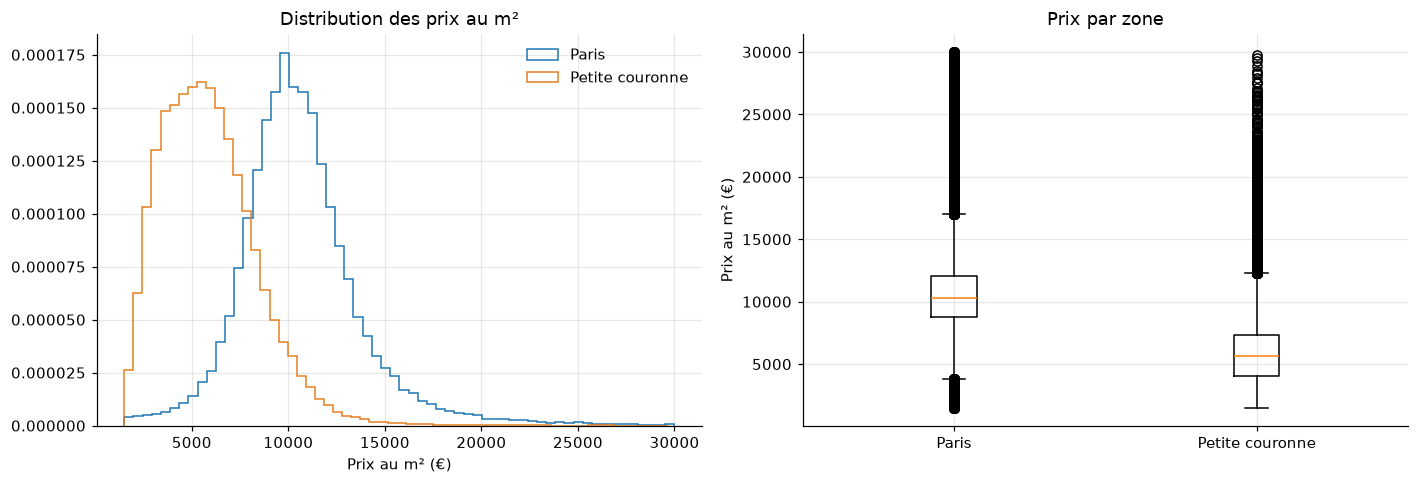

In [9]:
V.distribution_prix(df);

Paris compte 143 242 ventes (45 %) et la petite couronne 176 705. Les deux marchés sont très différents : le prix médian est de **10 314 €/m² à Paris** contre **5 625 €/m² en petite couronne**, et la distance médiane à une station est de **226 m à Paris** contre **694 m en petite couronne**.

C'est le premier piège de l'étude : les ventes parisiennes sont à la fois plus chères et plus proches des stations. Une comparaison qui mélange les deux zones attribuera donc à la distance une partie de l'écart Paris / petite couronne. C'est pourquoi la suite sépare toujours les deux zones, puis compare des ventes d'une même commune.

### 7. Relation générale entre distance et prix de vente

Les distances sont regroupées en tranches et on calcule le prix médian au m² de chaque tranche, avec son effectif. On commence par l'ensemble de la zone, puis on distingue Paris et la petite couronne.

In [10]:
analyse_100 = A.prix_par_tranche_fine(df, A.BORNES_100)
analyse_100

,zone,tranche,nombre_transactions,prix_median,prix_moyen
0,Paris,0-100,14548,"10,312.50","10,584.93"
1,Paris,100-200,43964,"10,434.78","10,711.41"
2,Paris,200-300,44319,"10,416.67","10,736.69"
3,Paris,300-400,25308,"10,242.72","10,575.91"
4,Paris,400-600,14082,"9,855.26","10,152.10"
5,Paris,600-800,1021,"9,101.56","9,093.95"
6,Petite couronne,0-100,2287,"6,666.67","6,952.64"
7,Petite couronne,100-200,8844,"6,578.95","6,723.72"
8,Petite couronne,200-300,14403,"6,437.50","6,724.78"
9,Petite couronne,300-400,16666,"6,328.03","6,585.02"


,tranche,nombre_transactions,prix_median,prix_moyen
0,0-100,16835,"9,986.79","10,091.49"
1,100-200,52808,"10,000.00","10,043.58"
2,200-300,58722,"9,705.72","9,752.67"
3,300-400,41974,"8,918.89","8,991.31"
4,400-600,47567,"7,266.67","7,525.43"
5,600-800,25979,"5,731.71","6,067.55"
6,800-1000,18503,"5,196.08","5,493.17"
7,1000-1500,28237,"4,897.96","5,200.71"
8,1500+,29322,"4,956.20","5,030.88"


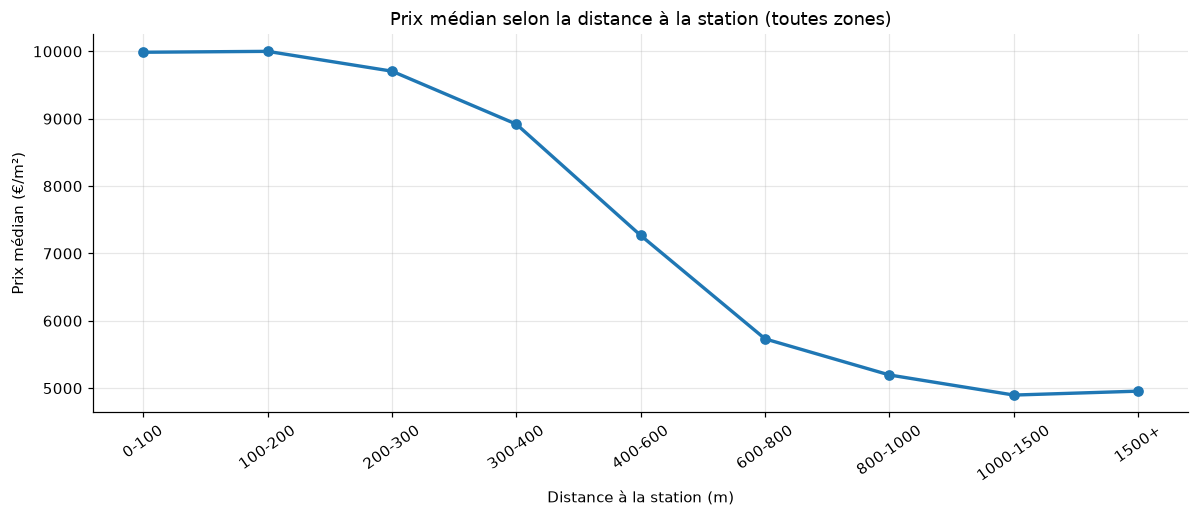

In [11]:
global_100 = A.prix_par_tranche_fine(df, A.BORNES_100, par_zone=False)
V.courbe_globale(global_100)
global_100

#### 7.1. Sur l'ensemble de la zone : un gradient surtout géographique

Sur l'ensemble, le prix médian est d'environ 10 000 €/m² jusqu'à 200 m d'une station, puis il chute : 8 919 €/m² à 300-400 m, 7 267 €/m² à 400-600 m et environ 4 900 à 5 200 €/m² au-delà de 800 m, soit à peu près deux fois moins.

Ce gradient ne mesure pas l'effet de la distance. Il traduit surtout le passage de Paris à la petite couronne : 86 % des ventes à moins de 100 m sont parisiennes, contre aucune au-delà de 800 m. Il faut donc séparer les deux zones.

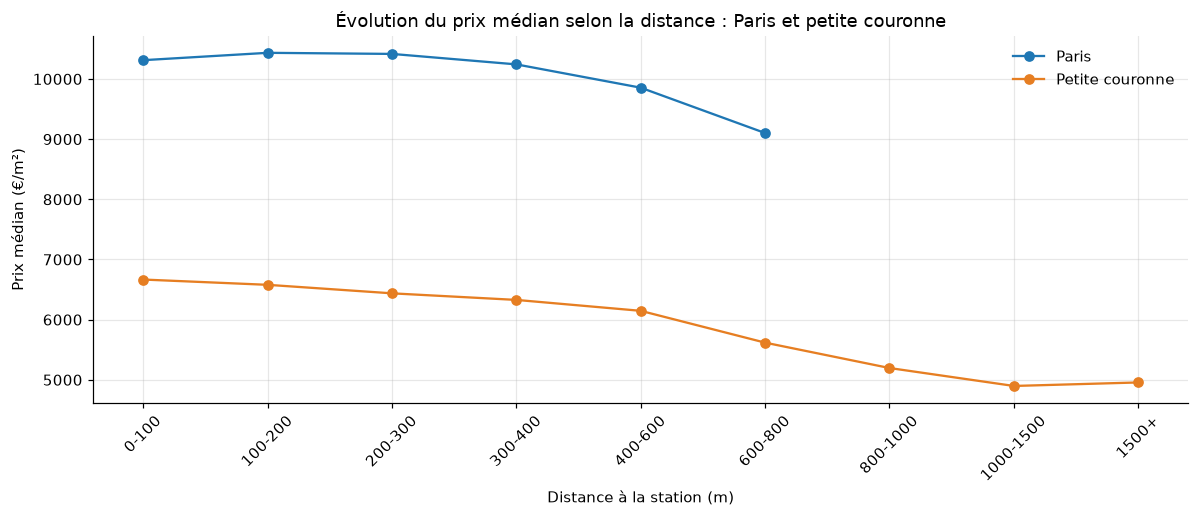

In [12]:
V.courbe_tranches(analyse_100, "prix_selon_distance_100m.png",
                  "Évolution du prix médian selon la distance : Paris et petite couronne");

#### 7.2. Paris et petite couronne séparément

**À Paris**, le prix médian est presque plat jusqu'à 400 m : il varie entre 10 243 et 10 435 €/m² (moins de 2 % d'écart), avec un maximum à 100-200 m. Il baisse ensuite : 9 855 €/m² à 400-600 m et 9 102 €/m² à 600-800 m, mais cette dernière tranche ne compte que 1 021 ventes. Aucune vente parisienne n'est à plus de 800 m d'une station.

**En petite couronne**, le prix médian le plus élevé est observé à moins de 100 m (6 667 €/m², 2 287 ventes), puis il diminue régulièrement : 6 328 €/m² à 300-400 m, 5 618 €/m² à 600-800 m et environ 4 900 €/m² au-delà de 1 000 m.

Ces deux profils bruts se lisent toutefois avec prudence : à l'intérieur de chaque zone, les ventes proches et éloignées ne sont pas non plus dans les mêmes communes. La section suivante le vérifie.

#### 7.3. Effet de composition : dans quelles communes sont les ventes de chaque tranche ?

Pour chaque vente, on calcule le prix médian de sa commune la même année. Si ce prix de commune varie d'une tranche de distance à l'autre, une partie de l'écart de prix brut entre tranches vient simplement de la localisation des ventes, et pas de la distance à la station.

In [13]:
import importlib
import vrai_prix.analysis as A

# Recharger le module depuis le fichier source
importlib.reload(A)

# Vérifier que la fonction est maintenant disponible
print(hasattr(A, "composition_tranches"))

True


In [14]:
composition = A.composition_tranches(df)
composition

,zone,tranche,n,prix_median_ventes,prix_median_commune
0,Paris,0-100,14548,"10,312.00","10,281.00"
1,Paris,100-200,43964,"10,435.00","10,309.00"
2,Paris,200-400,69627,"10,357.00","10,281.00"
3,Paris,400-600,14082,"9,855.00","10,000.00"
4,Paris,600-1000,1021,"9,102.00","9,694.00"
5,Petite couronne,0-100,2287,"6,667.00","6,500.00"
6,Petite couronne,100-200,8844,"6,579.00","6,405.00"
7,Petite couronne,200-400,31069,"6,375.00","6,265.00"
8,Petite couronne,400-600,33485,"6,147.00","6,182.00"
9,Petite couronne,600-1000,43461,"5,442.00","5,686.00"


En petite couronne, les ventes à moins de 100 m se trouvent dans des communes plus chères : le prix médian de leur commune est de **6 500 €/m²**, contre **6 265 €/m²** pour les ventes à 200-400 m et **5 686 €/m²** pour celles à 600-1 000 m. Entre 0-100 m et 200-400 m, l'écart brut est de +4,6 % (6 667 contre 6 375 €/m²), dont +3,7 % viennent déjà de la commune. Entre 200-400 m et 600-1 000 m, l'écart brut est de −14,6 %, dont −9,2 % viennent de la commune.

Le « maximum à moins de 100 m » de la petite couronne est donc pour l'essentiel un effet de composition. Le notebook 02, qui compare des ventes d'une même commune, d'une même année et d'une même taille, trouve même une légère décote à moins de 100 m (environ −3,5 %, avec un intervalle de confiance qui touche zéro).

À Paris, le prix médian des arrondissements est presque le même pour toutes les tranches jusqu'à 400 m (10 281 à 10 309 €/m²) : le plateau observé n'est pas un artefact de composition. Au-delà, les ventes sont dans des arrondissements un peu moins chers (9 694 €/m² à 600-1 000 m).

### 8. Analyse à granularité fine : tranches de 50 mètres

On réduit la largeur des tranches à 50 m pour voir si les maxima observés correspondent à une tendance régulière ou à un pic isolé. Les effectifs par tranche diminuent : ils sont toujours affichés.

In [15]:
analyse_50 = A.prix_par_tranche_fine(df, A.BORNES_50)
analyse_50

,zone,tranche,nombre_transactions,prix_median,prix_moyen
0,Paris,0-50,2891,"10,265.56","10,534.93"
1,Paris,50-100,11657,"10,326.11","10,597.33"
2,Paris,100-150,18762,"10,460.77","10,731.86"
3,Paris,150-200,25202,"10,416.67","10,696.19"
4,Paris,200-250,24499,"10,490.20","10,784.25"
5,Paris,250-300,19820,"10,333.33","10,677.90"
6,Paris,300-350,14402,"10,293.26","10,622.49"
7,Paris,350-400,10906,"10,181.82","10,514.40"
8,Paris,400-450,6987,"10,079.31","10,419.50"
9,Paris,450-500,3512,"9,879.83","10,151.48"


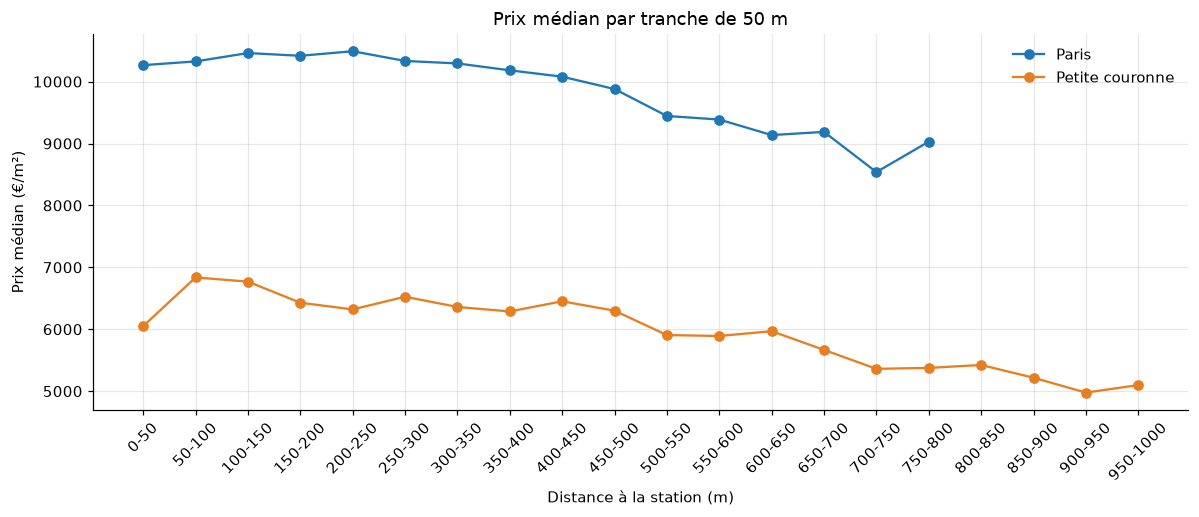

In [16]:
V.courbe_tranches(analyse_50, "prix_selon_distance_50m.png",
                  "Prix médian par tranche de 50 m", max_tranches=20);

In [17]:
A.meilleures_tranches(analyse_50, n_min=100)

,zone,tranche,nombre_transactions,prix_median,prix_moyen
4,Paris,200-250,24499,"10,490.20","10,784.25"
2,Paris,100-150,18762,"10,460.77","10,731.86"
3,Paris,150-200,25202,"10,416.67","10,696.19"
5,Paris,250-300,19820,"10,333.33","10,677.90"
1,Paris,50-100,11657,"10,326.11","10,597.33"
17,Petite couronne,50-100,1804,"6,837.10","7,031.68"
18,Petite couronne,100-150,3607,"6,769.23","6,888.33"
21,Petite couronne,250-300,7620,"6,525.23","6,765.42"
24,Petite couronne,400-450,8690,"6,451.61","6,675.06"
19,Petite couronne,150-200,5237,"6,428.57","6,610.34"


#### 8.1. Ce que montre le découpage en tranches de 50 m

À Paris, les cinq tranches les plus chères sont toutes entre 50 et 300 m, mais elles ne diffèrent que de 1,6 % (de 10 326 à 10 490 €/m²). Le maximum à 200-250 m n'a donc rien de remarquable : c'est le haut d'un plateau. La tranche la plus proche (0-50 m, 2 891 ventes) est un peu en dessous (10 266 €/m²).

En petite couronne, la courbe est irrégulière à courte distance. La tranche 0-50 m (483 ventes) est à 6 052 €/m², nettement sous la tranche 50-100 m (6 837 €/m², 1 804 ventes). Ensuite, des tranches voisines s'inversent : 6 429 €/m² à 150-200 m, puis 6 525 €/m² à 250-300 m. Des sauts de 2 à 3 % d'une tranche de 50 m à la suivante sont de l'ordre du bruit, d'autant que la position est celle du centre de la parcelle.

Le maximum d'une tranche fine ne peut donc pas être lu comme une « distance optimale ».

### 9. Évolution de la relation entre 2021 et 2025

On compare, pour chaque année et chaque zone, les prix médians des tranches de distance, puis leur évolution par rapport à 2021. Une variation d'une année à l'autre dépend aussi du marché (taux d'intérêt, conjoncture) et des biens vendus cette année-là.

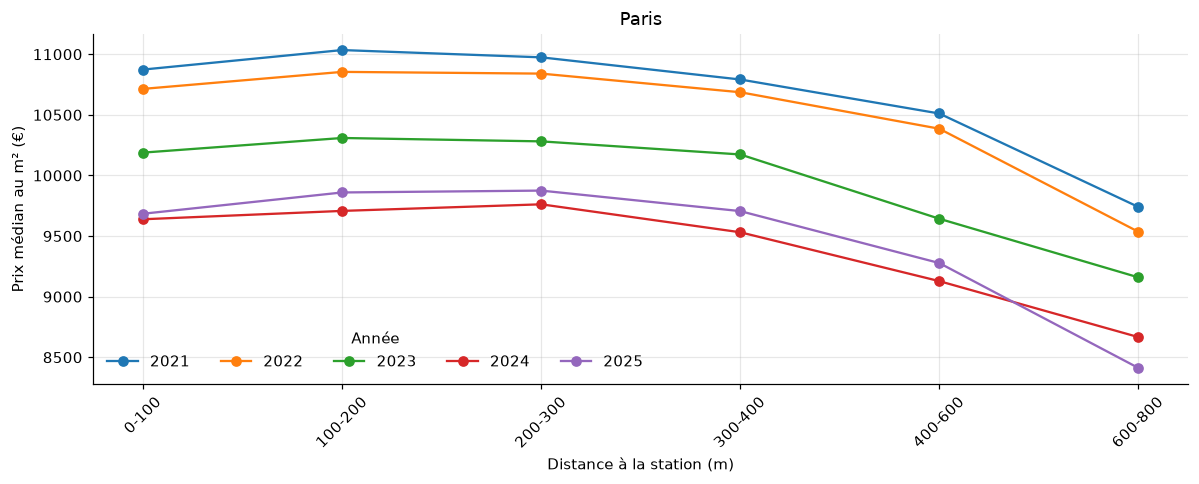

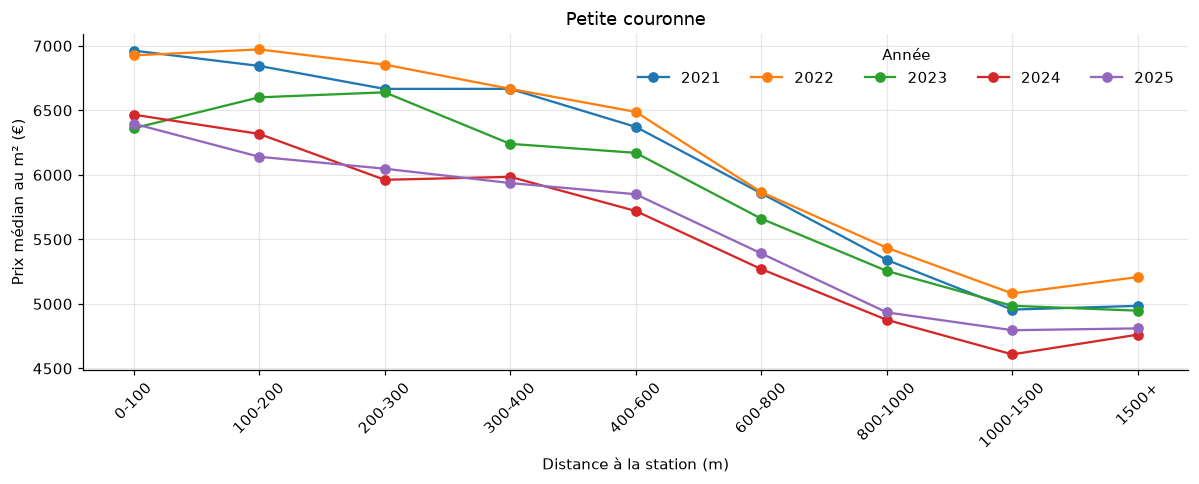

In [18]:
analyse_annuelle = A.evolution_annuelle(df)
V.courbes_par_annee(analyse_annuelle, "prix_median", "prix_distance_annee", "Prix médian au m² (€)");

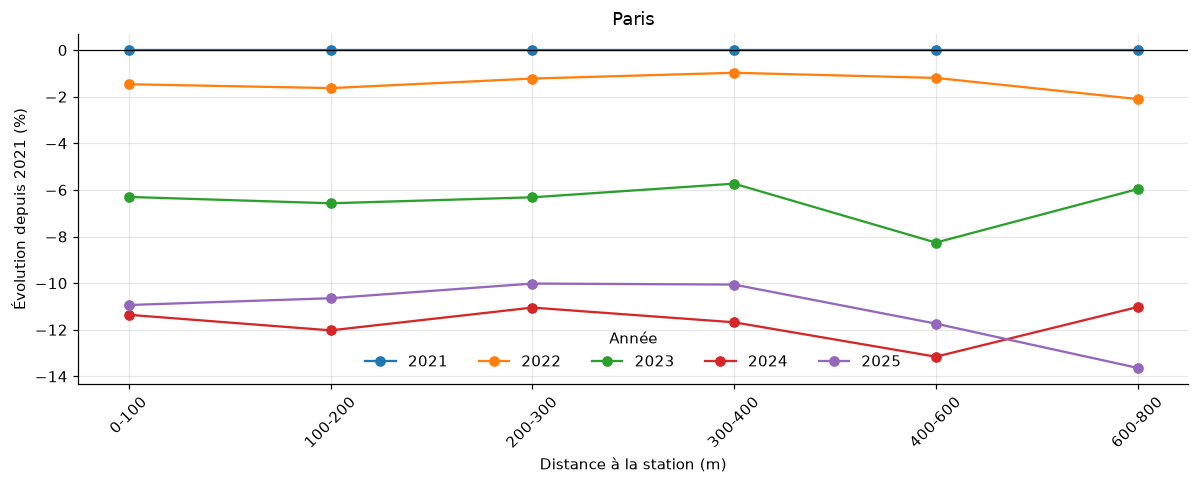

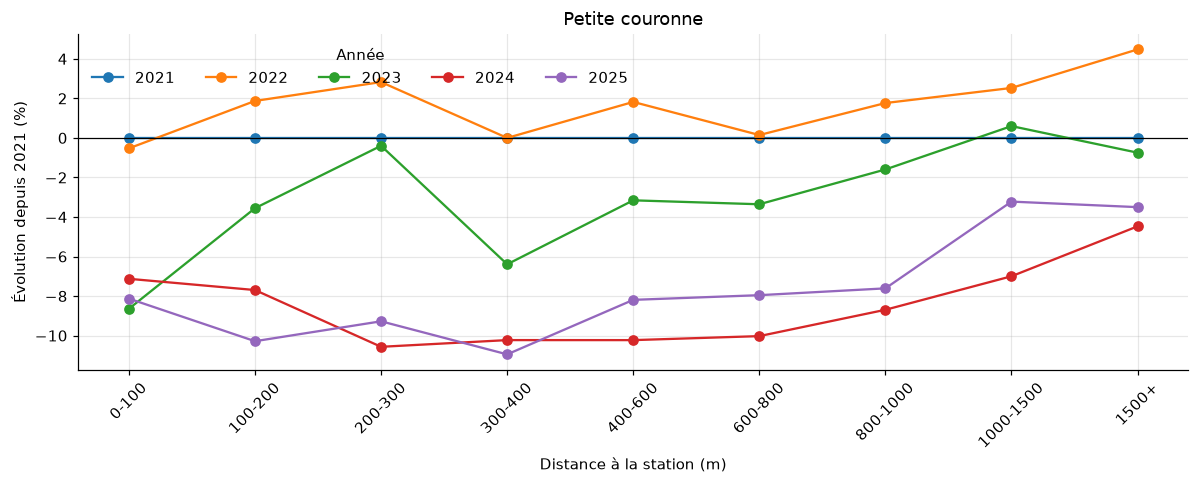

In [19]:
V.courbes_par_annee(analyse_annuelle, "evolution_depuis_2021_pct", "evolution_depuis_2021",
                    "Évolution depuis 2021 (%)");

In [20]:
analyse_annuelle.pivot_table(index=["zone", "tranche"], columns="annee",
                             values="evolution_depuis_2021_pct", observed=True).round(1)

annee                      2021  2022  2023   2024   2025
zone            tranche                                  
Paris           0-100      0.00 -1.50 -6.30 -11.40 -10.90
                100-200    0.00 -1.60 -6.60 -12.00 -10.60
                200-300    0.00 -1.20 -6.30 -11.00 -10.00
                300-400    0.00 -1.00 -5.70 -11.70 -10.10
                400-600    0.00 -1.20 -8.30 -13.20 -11.70
                600-800    0.00 -2.10 -6.00 -11.00 -13.60
Petite couronne 0-100      0.00 -0.50 -8.60  -7.10  -8.10
                100-200    0.00  1.90 -3.60  -7.70 -10.30
                200-300    0.00  2.80 -0.40 -10.60  -9.30
                300-400    0.00  0.00 -6.40 -10.20 -11.00
                400-600    0.00  1.80 -3.20 -10.20  -8.20
                600-800    0.00  0.10 -3.40 -10.00  -8.00
                800-1000   0.00  1.80 -1.60  -8.70  -7.60
                1000-1500  0.00  2.50  0.60  -7.00  -3.20
                1500+      0.00  4.50 -0.70  -4.50  -3.50

#### 9.1. Un profil stable dans un marché en baisse

Toutes les tranches baissent entre 2021 et 2025. **À Paris**, la baisse est très homogène : de −10,0 % à −11,7 % pour toutes les tranches jusqu'à 600 m, et −13,6 % à 600-800 m (tranche à faible effectif). La hiérarchie ne change pas : les tranches jusqu'à 400 m restent groupées chaque année, et 600-800 m reste la moins chère (de 9 741 €/m² en 2021 à 8 412 €/m² en 2025).

**En petite couronne**, les tranches proches baissent davantage que les tranches éloignées : de −7,6 % à −11,0 % jusqu'à 1 000 m, mais seulement −3,2 % à 1 000-1 500 m et −3,5 % au-delà de 1 500 m. L'écart brut entre proche et loin s'est donc un peu resserré.

Il ne faut pas en conclure que la prime de proximité diminue. Les ventes d'une année à l'autre ne sont pas les mêmes biens ni les mêmes communes. Quand on compare des ventes de même commune, même année et même taille (notebook 02, section 5), la prime de la petite couronne reste stable entre 7,2 % et 8,9 % selon l'année.

### 10. Analyse intra-communale : comparer à l'intérieur d'une même commune

Pour neutraliser les différences de niveau de prix entre communes, on compare, dans chaque commune, le prix médian de chaque tranche de 50 m à celui d'une tranche de référence située entre 200 et 400 m :

$$
\text{Écart}_{c,d} = \left(\frac{\text{Médiane}_{c,d}}{\text{Médiane}_{c,\text{ref}}} - 1\right) \times 100
$$

où $c$ désigne une commune, $d$ une tranche de distance et $\text{ref}$ la tranche 200-400 m. Un écart positif signifie que la tranche est plus chère que la référence dans la même commune. On ne garde que les couples (commune, tranche) d'au moins 30 ventes, avec au moins 30 ventes dans la référence.

Cette approche neutralise le niveau de prix de la commune, pas les différences entre quartiers, immeubles ou logements d'une même commune.

In [21]:
stats_commune = A.ecarts_communes(df)
print("Nombre de communes distinctes :", df["commune_id"].nunique())

Nombre de communes distinctes : 142


In [22]:
stats_commune_valides = stats_commune[(stats_commune["nombre_transactions"] >= 30)
                                      & (stats_commune["n_reference"] >= 30)]
stats_commune_valides.head()

,zone,commune_id,nom_commune,tranche,nombre_transactions,prix_median,prix_reference,n_reference,ecart_relatif_pct
1,Paris,75_75101,Paris 1er Arrondissement,50-100,147,"12,379.81","13,500.00",367.00,-8.30
2,Paris,75_75101,Paris 1er Arrondissement,100-150,370,"12,517.14","13,500.00",367.00,-7.28
3,Paris,75_75101,Paris 1er Arrondissement,150-200,484,"12,624.23","13,500.00",367.00,-6.49
4,Paris,75_75101,Paris 1er Arrondissement,200-250,203,"13,055.56","13,500.00",367.00,-3.29
5,Paris,75_75101,Paris 1er Arrondissement,250-300,53,"13,735.10","13,500.00",367.00,1.74


In [23]:
synthese_intra = A.synthese_ecarts(stats_commune, seuil=30)
synthese_intra

,zone,tranche,nombre_communes,ecart_median_pct,ecart_moyen_pct,part_communes_positives,seuil_effectif
0,Paris,0-50,18,0.62,-0.35,50.00,30
1,Paris,50-100,20,-1.36,-1.28,30.00,30
2,Paris,100-150,20,-0.80,-0.79,45.00,30
3,Paris,150-200,20,-0.72,-1.58,35.00,30
4,Paris,200-250,20,-0.20,-0.50,45.00,30
5,Paris,250-300,20,0.42,0.75,50.00,30
6,Paris,300-350,19,0.46,1.03,68.42,30
7,Paris,350-400,19,-0.39,0.53,42.11,30
8,Paris,400-450,15,-0.66,-0.25,33.33,30
9,Paris,450-500,12,0.18,1.10,50.00,30


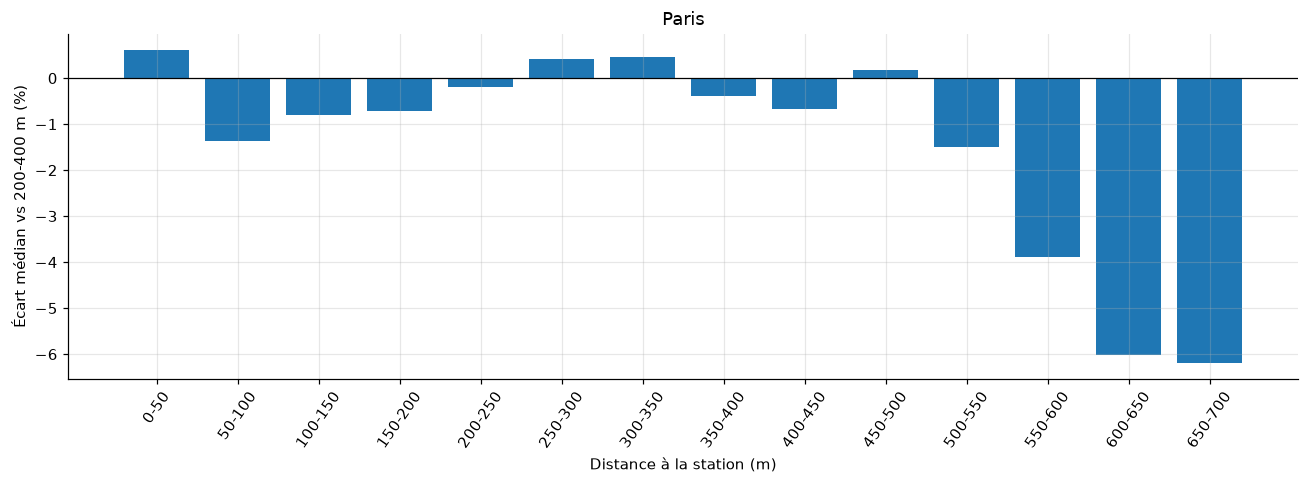

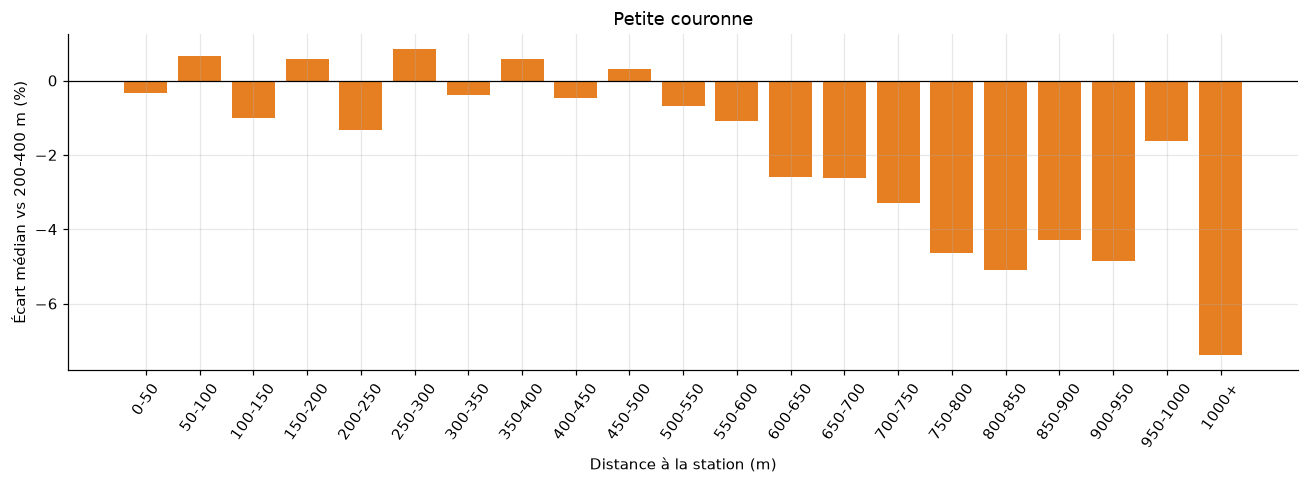

In [24]:
V.ecarts_communes_barres(synthese_intra);

#### 10.1. Un plateau jusqu'à environ 500-600 m, puis une baisse

**À Paris**, jusqu'à 500 m, l'écart médian entre arrondissements reste compris entre −1,4 % et +0,6 %, et la part d'arrondissements où la tranche est plus chère que la référence varie de 30 % à 68 %. Aucune tranche proche ne se détache. Au-delà de 550 m, les écarts deviennent nettement négatifs (−3,9 % à −6,2 %), mais sur 2 à 7 arrondissements seulement.

**En petite couronne**, jusqu'à 600 m, l'écart médian reste entre −1,3 % et +0,8 %, et son signe change d'une tranche de 50 m à la suivante. Au-delà de 600 m, il est négatif dans toutes les tranches : entre −1,6 % et −5,1 % jusqu'à 1 000 m, et −7,4 % au-delà. La part de communes positives y tombe entre 31 % et 44 %.

À l'intérieur des communes, la proximité immédiate n'est pas favorisée : en petite couronne, l'écart médian est de −0,3 % à 0-50 m (6 communes) et de +0,7 % à 50-100 m (23 communes). Le maximum brut à moins de 100 m de la section 7.2 disparaît donc quand on compare à l'intérieur des communes, ce qui confirme l'effet de composition de la section 7.3.

### 11. Recherche d'intervalles de distance particulièrement valorisés

On cherche des **séquences d'au moins deux tranches de 50 m consécutives** qui soient plus chères que la référence 200-400 m dans la plupart des communes. Une tranche est jugée favorable si :

- son écart médian à la référence est positif ;
- plus de la moitié des communes représentées ont un écart positif ;
- elle est représentée dans assez de communes (au moins 10 à Paris, 20 en petite couronne).

Le critère est exigeant par construction : la référence 200-400 m se trouve elle-même au milieu du plateau mis en évidence à la section 10. Une tranche favorable doit donc être plus chère que ce plateau, pas seulement plus chère que les tranches éloignées. On répète la recherche pour quatre seuils d'effectif minimal (20, 30, 50 et 100 ventes).

In [25]:
seuils = [20, 30, 50, 100]
resultats_robustesse = A.robustesse_seuils(stats_commune, seuils)
resultats_robustesse

,zone,tranche,nombre_communes,ecart_median_pct,ecart_moyen_pct,part_communes_positives,seuil_effectif
0,Paris,0-50,19,-0.28,-0.35,47.37,20
1,Paris,50-100,20,-1.36,-1.28,30.00,20
2,Paris,100-150,20,-0.80,-0.79,45.00,20
3,Paris,150-200,20,-0.72,-1.58,35.00,20
4,Paris,200-250,20,-0.20,-0.50,45.00,20
...,...,...,...,...,...,...,...
134,Petite couronne,800-850,17,-1.90,-0.24,41.18,100
135,Petite couronne,850-900,14,-5.41,-5.47,35.71,100
136,Petite couronne,900-950,13,-3.86,-3.50,38.46,100
137,Petite couronne,950-1000,12,-4.68,-1.84,41.67,100


In [26]:
intervalles_detectes = pd.concat([A.detecter_intervalles(resultats_robustesse, s) for s in seuils],
                                 ignore_index=True)
if intervalles_detectes.empty:
    print("Résultat : aucune séquence d'au moins deux tranches consécutives ne remplit les critères, "
          "quel que soit le seuil (20, 30, 50 ou 100 ventes).")
display(intervalles_detectes)

# Tranches qui remplissent les critères isolément (sans voisine favorable)
favorables_isolees = resultats_robustesse[(resultats_robustesse["ecart_median_pct"] > 0)
                                          & (resultats_robustesse["part_communes_positives"] > 50)]
favorables_isolees.pivot_table(index=["zone", "tranche"], columns="seuil_effectif",
                               values="ecart_median_pct", observed=True).round(2)

Résultat : aucune séquence d'au moins deux tranches consécutives ne remplit les critères, quel que soit le seuil (20, 30, 50 ou 100 ventes).


,zone,seuil_effectif,debut_m,fin_m,n_tranches,ecart_median_moyen_pct,part_positive_moyenne_pct


seuil_effectif           20   30   50   100
zone            tranche                    
Paris           0-50     NaN  NaN  NaN 1.78
                300-350 0.46 0.46 0.46 0.39
Petite couronne 50-100  1.42 0.65 0.94  NaN
                150-200 0.57 0.57 0.72  NaN
                250-300 0.44 0.84 0.84 0.37
                350-400 0.82 0.57 0.20  NaN
                450-500 0.42 0.31 0.31  NaN

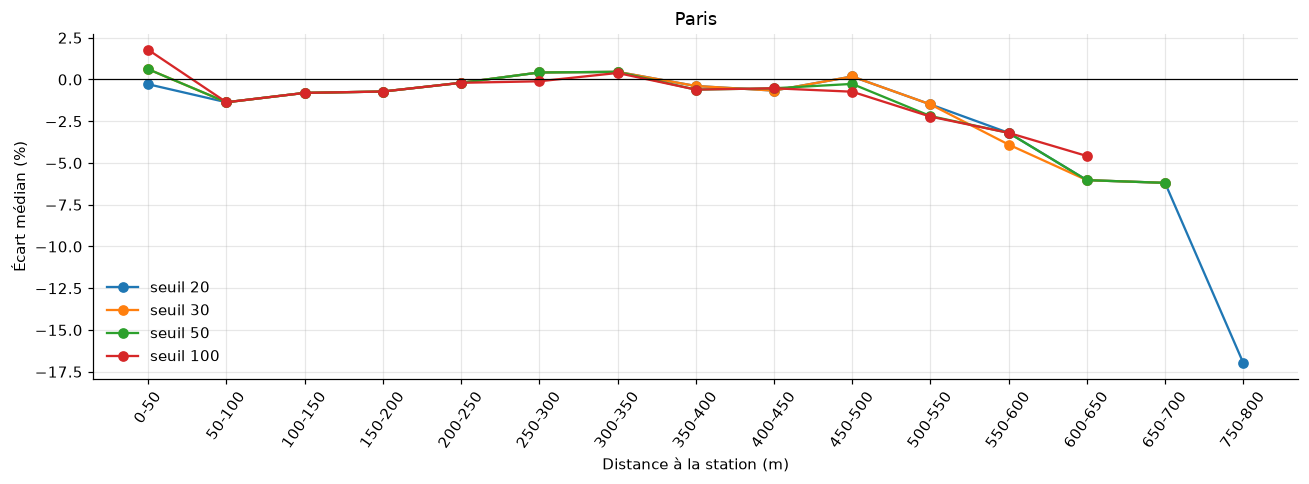

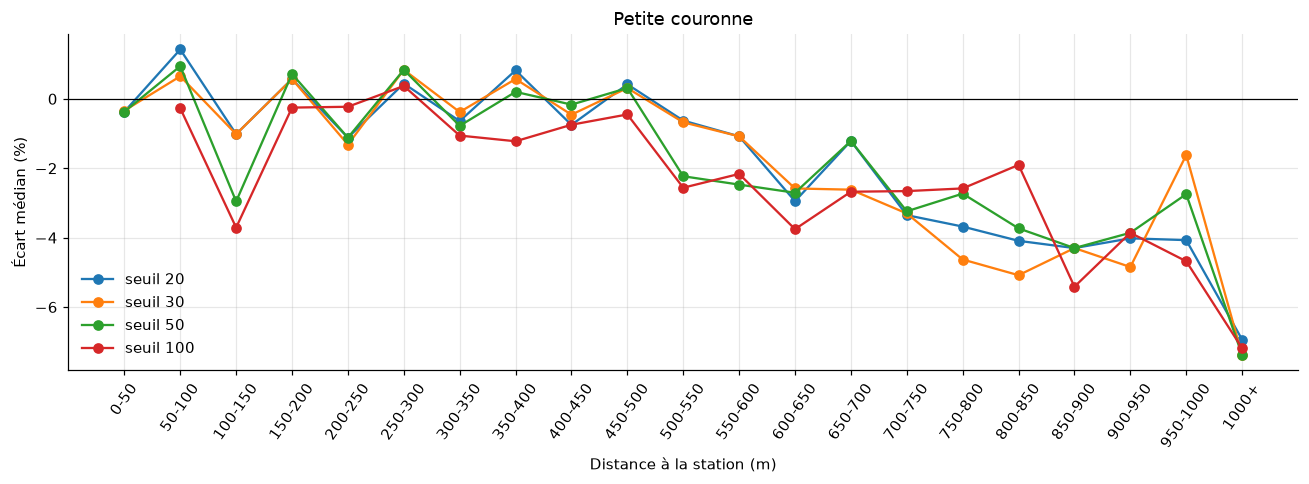

In [27]:
V.sensibilite_seuils(resultats_robustesse);

#### 11.1. Résultat : aucun intervalle favorable

**La recherche ne renvoie rien** : pour aucun des quatre seuils, deux tranches consécutives ne sont à la fois au-dessus de la référence et favorables dans la majorité des communes.

Des tranches favorables existent isolément, mais elles ne forment pas de séquence. En petite couronne, ce sont une tranche sur deux entre 50 et 500 m (50-100, 150-200, 250-300, 350-400 et 450-500 m), séparées par des tranches défavorables. Cette alternance est la signature du bruit, pas d'une distance valorisée. Leurs écarts médians sont faibles (+0,2 % à +1,4 %). À Paris, seule la tranche 300-350 m remplit les critères (+0,4 % à +0,5 % selon le seuil), avec 0-50 m au seuil de 100 ventes.

Le graphique de sensibilité montre en revanche un résultat stable pour tous les seuils : la baisse au-delà de 550-600 m. **L'affirmation selon laquelle une distance précise (par exemple 100-400 m) serait « la plus valorisée » n'est donc pas soutenue par les données.** Ce qui est soutenu, c'est un plateau jusqu'à environ 500-600 m, puis une baisse.

### 12. Métro contre RER

On compare le prix médian selon la distance pour les ventes dont la station la plus proche est une station de métro seule ou de RER seul. Les stations desservies par les deux modes (11 844 ventes) sont exclues.

,part des ventes à Paris (%)
mode_station,
METRO,60.70
RER,5.80


,n_METRO,n_RER,mediane_METRO,mediane_RER,ecart_METRO_moins_RER,ratio_METRO_sur_RER
tranche,,,,,,
0-200,"63,334.00","4,985.00","10,058.82","6,234.04","3,824.78",1.61
200-400,"84,064.00","13,541.00","9,714.29","5,650.00","4,064.29",1.72
400-600,"32,455.00","13,120.00","8,136.36","5,153.85","2,982.51",1.58
600-800,"13,235.00","11,870.00","6,881.58","4,640.31","2,241.27",1.48
800-1000,"7,659.00","10,217.00","6,489.36","4,302.33","2,187.03",1.51
1000-1500,"9,434.00","17,474.00","6,458.33","4,140.31","2,318.02",1.56
1500+,"9,251.00","17,464.00","5,867.57","4,073.17","1,794.40",1.44


,mode,n,mediane_0-200,mediane_600-800,ecart_%,correlation_spearman
0,METRO,219432,"10,058.82","6,881.58",-31.59,-0.41
1,RER,88671,"6,234.04","4,640.31",-25.56,-0.30


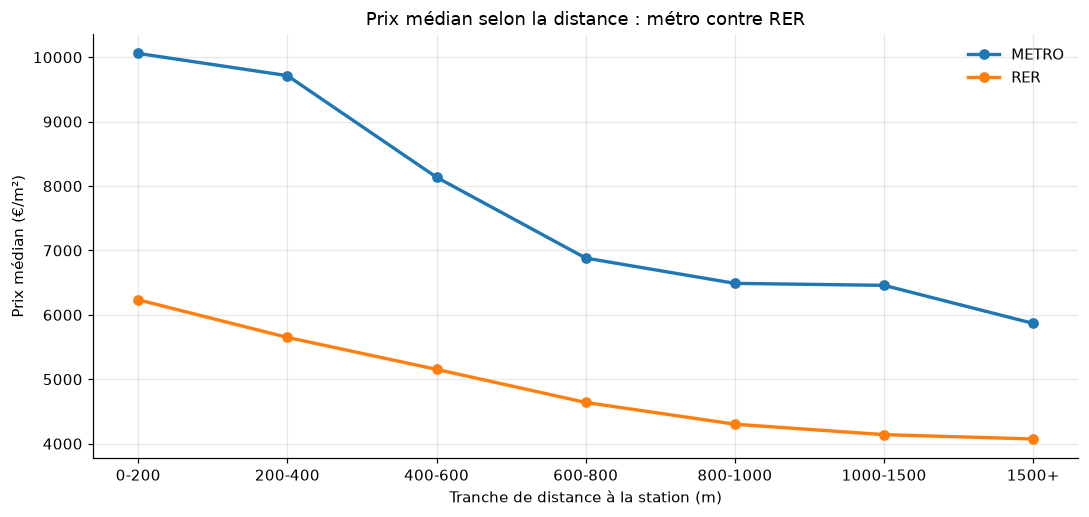

In [28]:
resume_modes, pentes_modes, courbe_modes = A.comparaison_modes(df)
V.courbe_modes(courbe_modes)

part_paris = (df.assign(mode_station=df["modes_station"].map(A.extraire_mode))
                .query("mode_station in ['METRO', 'RER']")
                .groupby("mode_station")["zone"].apply(lambda z: (z == "Paris").mean() * 100)
                .round(1).rename("part des ventes à Paris (%)"))
display(part_paris.to_frame())

tableau_modes = resume_modes[["n_METRO", "n_RER", "mediane_METRO", "mediane_RER"]].copy()
tableau_modes["ecart_METRO_moins_RER"] = tableau_modes["mediane_METRO"] - tableau_modes["mediane_RER"]
tableau_modes["ratio_METRO_sur_RER"] = tableau_modes["mediane_METRO"] / tableau_modes["mediane_RER"]
display(tableau_modes.round(2))
pentes_modes

#### 12.1. Sur l'ensemble : un écart qui mélange mode et territoire

Sur l'ensemble des ventes, à distance égale, le prix médian autour du métro est 1,44 à 1,72 fois celui autour du RER. L'écart va de 1 794 €/m² (au-delà de 1 500 m) à 4 064 €/m² (200-400 m : 9 714 contre 5 650 €/m²). Le prix baisse aussi plus vite avec la distance autour du métro : −31,6 % entre 0-200 m et 600-800 m, contre −25,6 % pour le RER.

Mais **61 % des ventes « métro » sont à Paris, contre 6 % des ventes « RER »**. Comparer les deux modes sur l'ensemble revient surtout à comparer Paris à la petite couronne. Il faut donc refaire la comparaison à zone constante.

,zone,tranche,mediane_METRO,mediane_RER,n_METRO,n_RER,ecart_RER_vs_METRO_%
0,Paris,0-200,"10,361.60","11,840.00","55,918.00","1,369.00",14.30
1,Paris,200-400,"10,312.50","11,734.30","64,150.00","2,751.00",13.80
2,Paris,400-600,"9,787.20","10,782.60","12,138.00",963.00,10.20
3,Paris,600-800,"9,123.60","8,727.30",888.00,55.00,-4.30
4,Petite couronne,0-200,"7,368.40","5,263.20","7,416.00","3,616.00",-28.60
5,Petite couronne,200-400,"7,250.00","5,084.40","19,914.00","10,790.00",-29.90
6,Petite couronne,400-600,"7,011.40","5,000.00","20,317.00","12,157.00",-28.70
7,Petite couronne,600-800,"6,714.30","4,629.60","12,347.00","11,815.00",-31.00
8,Petite couronne,800-1000,"6,489.40","4,302.30","7,659.00","10,217.00",-33.70
9,Petite couronne,1000-1500,"6,458.30","4,140.30","9,434.00","17,474.00",-35.90


,zone,mode,tranche_depart,tranche_arrivee,mediane_depart,mediane_arrivee,baisse_%
0,Paris,METRO,0-200,600-800,"10,361.60","9,123.60",-11.90
1,Paris,RER,0-200,600-800,"11,840.00","8,727.30",-26.30
2,Petite couronne,METRO,0-200,1500+,"7,368.40","5,867.60",-20.40
3,Petite couronne,RER,0-200,1500+,"5,263.20","4,073.20",-22.60


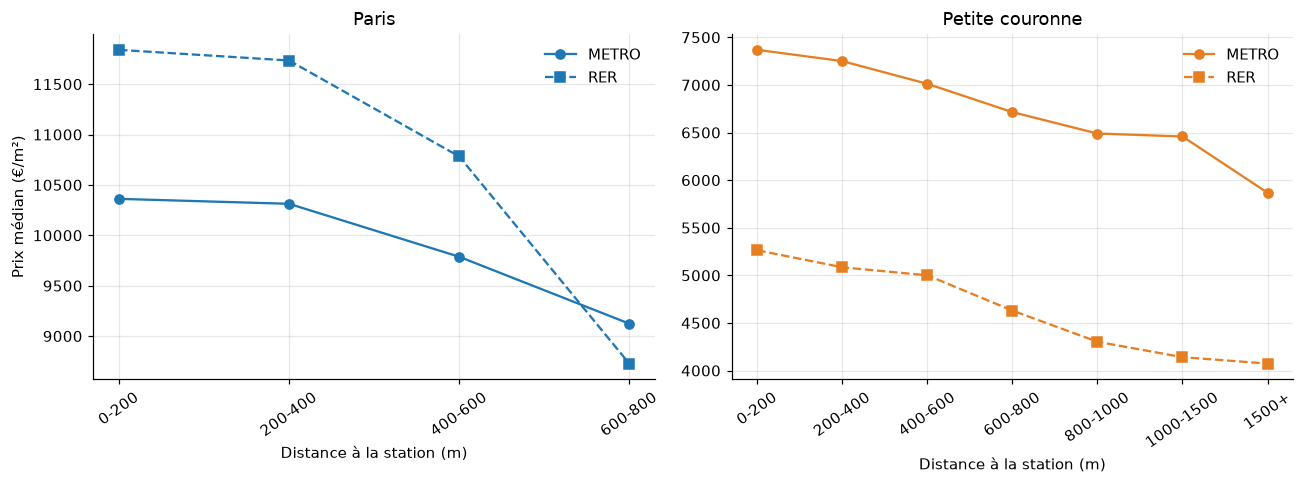

In [29]:
modes_zone = A.modes_par_zone(df)
V.courbe_modes_par_zone(modes_zone)
display(modes_zone)
baisse_modes = A.baisse_modes_par_zone(df)
baisse_modes

#### 12.2. À zone constante, la conclusion s'inverse

**En petite couronne**, le métro reste plus cher que le RER à toutes les distances (le RER est 29 % à 36 % moins cher), mais la baisse avec la distance n'est pas plus marquée pour le métro : entre 0-200 m et plus de 1 500 m, le prix médian passe de 7 368 à 5 868 €/m² pour le métro (−20,4 %) et de 5 263 à 4 073 €/m² pour le RER (−22,6 %).

**À Paris**, le RER seul est *plus* cher que le métro jusqu'à 600 m (+10 % à +14 %). Les stations concernées sont surtout celles du RER C dans l'ouest (Boulainvilliers, Avenue du Président Kennedy, Pont de l'Alma, Avenue Henri Martin) et du RER B au centre (Luxembourg, Port-Royal), dans des quartiers chers. Les effectifs RER parisiens sont faibles (55 à 2 751 ventes par tranche).

La « décroissance plus marquée pour le métro » observée sur l'ensemble vient donc du mélange entre Paris et la petite couronne. L'écart de niveau entre métro et RER reflète surtout des différences de territoire : on ne peut pas l'attribuer au mode de transport.

### 13. Limites et précautions d'interprétation

1. **Une relation descriptive, pas causale.** Les stations sont implantées dans des zones déjà denses et recherchées : on observe des associations, pas l'effet d'une station sur le prix.
2. **Des biens différents.** Le DVF ne contient ni l'étage, ni l'état, ni l'année de construction, ni la présence d'un balcon. Deux ventes d'une même tranche peuvent différer sur tous ces points.
3. **Des effets de composition.** Les ventes proches et éloignées ne sont pas dans les mêmes communes (section 7.3). Les comparaisons brutes par tranche en sont affectées. Les comparaisons intra-communales (section 10) et le notebook 02 réduisent ce problème sans l'éliminer, car les quartiers d'une même commune diffèrent aussi.
4. **Des effectifs très inégaux.** À Paris, presque toutes les ventes sont à moins de 600 m d'une station et aucune à plus de 800 m. En petite couronne, peu de ventes sont à moins de 100 m (2 287).
5. **Une composition qui change dans le temps.** Les biens vendus ne sont pas les mêmes d'une année à l'autre.
6. **Une mesure simplifiée de l'accessibilité.** Distance à vol d'oiseau depuis le centre de la parcelle, sans temps de marche, fréquence ni nombre de lignes.
7. **Métro et RER seulement.** Le tramway et le Transilien ne sont pas pris en compte. En petite couronne, un logement proche d'un tram ou d'une gare Transilien est compté « loin », ce qui atténue les écarts.
8. **Pas de mesure d'incertitude ici.** Les écarts de ce notebook sont des points d'estimation. Les intervalles de confiance sont calculés dans le notebook 02. Ils montrent que des écarts de l'ordre de 1 % entre tranches proches sont indiscernables du bruit.

### 14. Conclusion

Ce notebook décrit la relation entre la distance à la station de métro ou de RER la plus proche et le prix au m² des appartements, à partir de 319 947 ventes de 2021 à 2025.

1. **Le gradient global est surtout géographique.** Sur l'ensemble, le prix médian est divisé par deux entre les ventes proches des stations et celles à plus de 800 m. Mais les ventes proches sont surtout parisiennes, et les ventes éloignées toutes en petite couronne.

2. **À Paris, le prix est plat jusqu'à 400 m, puis baisse.** Les tranches jusqu'à 400 m diffèrent de moins de 2 %, et leurs arrondissements ont le même niveau de prix. La baisse au-delà de 400-600 m repose sur peu de ventes.

3. **En petite couronne, le maximum brut à moins de 100 m est un effet de composition.** Ces ventes sont situées dans des communes plus chères (6 500 €/m² contre 6 265 €/m² pour la tranche 200-400 m). À l'intérieur des communes, la proximité immédiate n'est pas plus chère, et le notebook 02 y trouve même une légère décote, non significative.

4. **Aucune distance optimale n'est identifiée.** La recherche d'intervalles favorables ne renvoie rien, quel que soit le seuil d'effectif, et les tranches favorables isolées alternent avec des tranches défavorables. Le seul résultat stable est un **plateau jusqu'à environ 500-600 m, suivi d'une baisse** de quelques pourcents (écarts médians de −1,6 % à −7,4 % dans les communes de petite couronne au-delà de 600 m).

5. **Le profil est stable dans le temps.** De 2021 à 2025, tous les prix baissent (−10 à −14 % à Paris, −3 à −11 % en petite couronne). La hiérarchie des tranches ne change pas à Paris, et le léger resserrement brut observé en petite couronne ne se retrouve pas à biens comparables (notebook 02).

6. **L'écart métro / RER est un écart de territoire.** À zone constante, la baisse avec la distance est semblable pour les deux modes en petite couronne (−20 % et −23 %), et à Paris les stations de RER seul sont même plus chères.

Ces résultats restent descriptifs et ne portent que sur le métro et le RER. Le notebook 02 les chiffre à biens comparables, avec des intervalles de confiance.

In [30]:
A.sauver(entonnoir, "entonnoir_nettoyage.csv")
A.sauver(analyse_100, "prix_distance_100m.csv", index=False)
A.sauver(analyse_50, "prix_distance_50m.csv", index=False)
A.sauver(composition, "composition_tranches.csv", index=False)
A.sauver(analyse_annuelle, "prix_distance_annuel.csv", index=False)
A.sauver(stats_commune_valides, "ecarts_intra_communaux.csv", index=False)
A.sauver(resultats_robustesse, "robustesse_seuils.csv", index=False)
A.sauver(intervalles_detectes, "intervalles_favorables.csv", index=False)
A.sauver(modes_zone, "metro_rer_par_zone.csv", index=False)
print("Tableaux enregistrés dans", A.TABLES.relative_to(ROOT))

Tableaux enregistrés dans outputs/Tables


In [31]:
print(f"Transactions analysées : {len(df):,} | communes : {df['commune_id'].nunique()} | "
      f"période : {df['annee'].min()}-{df['annee'].max()}".replace(",", " "))
df.groupby(["zone", "annee"]).size().unstack(fill_value=0)

Transactions analysées : 319 947 | communes : 142 | période : 2021-2025


annee,2021,2022,2023,2024,2025
zone,,,,,
Paris,30427,33138,26861,24460,28356
Petite couronne,41244,41669,32013,27911,33868
